## Ejercicio hiperparametrización breast cancer de sklearn

1. Carga el dataset [breast_cancer de `sklearn`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)
2. Prueba al menos 5 modelos diferentes de clasificación y aplica un GridSearchCV mediante Pipelines. Aplica también un RandomizedSearchCV.
3. Conclusiones. Guarda el modelo final en un archivo con pickle.

In [5]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

In [6]:
%matplotlib inline
data = load_breast_cancer()
data

{'data': array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
         1.189e-01],
        [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
         8.902e-02],
        [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
         8.758e-02],
        ...,
        [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
         7.820e-02],
        [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
         1.240e-01],
        [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
         7.039e-02]], shape=(569, 30)),
 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
        1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
        1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
        1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1,

In [7]:
data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [8]:
print(data['DESCR'])

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

In [9]:
df = pd.DataFrame(data['data'], columns=data['feature_names'])
df['target'] = data['target']
df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0


In [10]:
# 1. Preparación de los datos: reservamos el test para la evaluación final
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from scipy.stats import loguniform, randint
import pickle

X = df.drop(columns='target')
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print(f'Entrenamiento: {X_train.shape}; test: {X_test.shape}')
print('Clases:', dict(y.value_counts()))

Entrenamiento: (455, 30); test: (114, 30)
Clases: {1: np.int64(357), 0: np.int64(212)}


### GridSearchCV con cinco clasificadores

El escalado está dentro del `Pipeline`, así que cada partición de validación cruzada aprende sus propios parámetros y se evita fuga de información.

In [11]:
# 2. GridSearchCV: un único pipeline y cinco familias de modelos
pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=10_000, random_state=42))
])

param_grid = [
    {'model': [LogisticRegression(max_iter=10_000, random_state=42)],
     'model__C': [0.01, 0.1, 1, 10], 'model__penalty': ['l1', 'l2'],
     'model__solver': ['liblinear']},
    {'model': [KNeighborsClassifier()],
     'model__n_neighbors': [3, 5, 7, 11], 'model__weights': ['uniform', 'distance'],
     'model__p': [1, 2]},
    {'model': [SVC(probability=True, random_state=42)],
     'model__C': [0.1, 1, 10], 'model__kernel': ['linear', 'rbf'],
     'model__gamma': ['scale', 'auto']},
    {'model': [RandomForestClassifier(random_state=42, n_jobs=1)],
     'model__n_estimators': [100, 250], 'model__max_depth': [None, 5, 10],
     'model__min_samples_split': [2, 5]},
    {'model': [GradientBoostingClassifier(random_state=42)],
     'model__n_estimators': [100, 200], 'model__learning_rate': [0.03, 0.1],
     'model__max_depth': [2, 3]}
]

grid_search = GridSearchCV(
    estimator=pipe, param_grid=param_grid, scoring='f1', cv=5,
    n_jobs=-1, return_train_score=True
)
grid_search.fit(X_train, y_train)
print('Mejor F1-CV (Grid):', round(grid_search.best_score_, 4))
print('Mejores parámetros:', grid_search.best_params_)

/Users/fyeray/miniforge3/envs/machine-learning/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/fyeray/miniforge3/envs/machine-learning/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/fyeray/miniforge3/envs/machine-learning/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its d

Mejor F1-CV (Grid): 0.9843
Mejores parámetros: {'model': LogisticRegression(max_iter=10000, random_state=42), 'model__C': 1, 'model__penalty': 'l2', 'model__solver': 'liblinear'}


/Users/fyeray/miniforge3/envs/machine-learning/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [12]:
# Resumen del mejor resultado de cada familia de modelos
resultados_grid = pd.DataFrame(grid_search.cv_results_)
resultados_grid['modelo'] = resultados_grid['param_model'].astype(str).str.extract(r'^(\w+)')[0]
resumen_grid = (resultados_grid.sort_values('rank_test_score')
                .groupby('modelo', as_index=False).first()
                [['modelo', 'mean_test_score', 'std_test_score', 'params']]
                .sort_values('mean_test_score', ascending=False))
resumen_grid.columns = ['modelo', 'f1_cv_media', 'f1_cv_std', 'mejores_parametros']
resumen_grid

,modelo,f1_cv_media,f1_cv_std,mejores_parametros
2,LogisticRegression,0.984344,0.010069,"{'model': LogisticRegression(max_iter=10000, r..."
4,SVC,0.982755,0.010697,"{'model': SVC(probability=True, random_state=4..."
1,KNeighborsClassifier,0.977478,0.015009,"{'model': KNeighborsClassifier(), 'model__n_ne..."
0,GradientBoostingClassifier,0.977448,0.011470,{'model': GradientBoostingClassifier(random_st...
3,RandomForestClassifier,0.968444,0.015105,"{'model': RandomForestClassifier(n_jobs=1, ran..."


### RandomizedSearchCV

Para mostrar una alternativa menos costosa al grid exhaustivo, se explora el espacio de hiperparámetros de un SVC mediante distribuciones.

In [13]:
# 3. RandomizedSearchCV sobre SVC
random_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', SVC(probability=True, random_state=42))
])
random_params = {
    'model__C': loguniform(1e-3, 1e3),
    'model__gamma': loguniform(1e-4, 1),
    'model__kernel': ['rbf', 'linear'],
    'model__class_weight': [None, 'balanced']
}
random_search = RandomizedSearchCV(
    estimator=random_pipe, param_distributions=random_params, n_iter=30,
    scoring='f1', cv=5, n_jobs=-1, random_state=42
)
random_search.fit(X_train, y_train)
print('Mejor F1-CV (Randomized):', round(random_search.best_score_, 4))
print('Mejores parámetros:', random_search.best_params_)

/Users/fyeray/miniforge3/envs/machine-learning/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/fyeray/miniforge3/envs/machine-learning/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/fyeray/miniforge3/envs/machine-learning/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/fyeray/miniforge3/envs/machine-learning/lib/python3.11/site-packages/

Mejor F1-CV (Randomized): 0.9845
Mejores parámetros: {'model__C': np.float64(0.06724850206557247), 'model__class_weight': None, 'model__gamma': np.float64(0.0008386394780402561), 'model__kernel': 'linear'}


/Users/fyeray/miniforge3/envs/machine-learning/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/fyeray/miniforge3/envs/machine-learning/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/fyeray/miniforge3/envs/machine-learning/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/fyeray/miniforge3/envs/machine-learning/lib/python3.11/site-packages/

Búsqueda seleccionada: RandomizedSearchCV
Accuracy en test: 0.9825
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



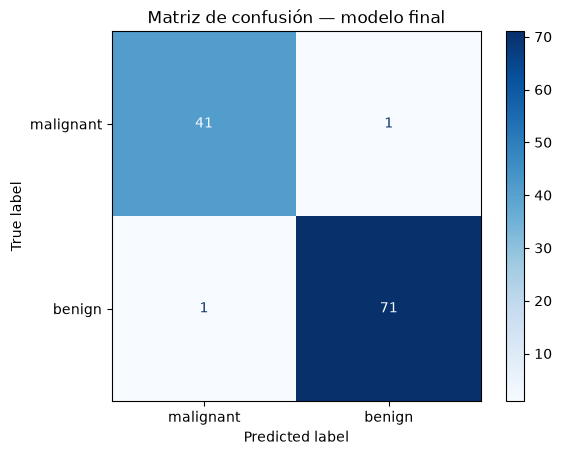

In [14]:
# 4. Selección del buscador ganador y evaluación una única vez en test
best_search = max([grid_search, random_search], key=lambda search: search.best_score_)
final_model = best_search.best_estimator_
y_pred = final_model.predict(X_test)

print('Búsqueda seleccionada:', type(best_search).__name__)
print('Accuracy en test:', round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=data.target_names))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=data.target_names, cmap='Blues')
plt.title('Matriz de confusión — modelo final')
plt.show()

In [15]:
# 5. Persistencia del pipeline completo (preprocesado + clasificador)
model_path = 'breast_cancer_pipeline.pkl'
with open(model_path, 'wb') as file:
    pickle.dump(final_model, file)

# Comprobación de que el fichero se puede recuperar y predecir
with open(model_path, 'rb') as file:
    loaded_model = pickle.load(file)
assert np.array_equal(loaded_model.predict(X_test), y_pred)
print(f'Modelo guardado y verificado en: {model_path}')

Modelo guardado y verificado en: breast_cancer_pipeline.pkl


### Conclusiones

- Se compararon Logistic Regression, KNN, SVC, Random Forest y Gradient Boosting usando validación cruzada estratificada de 5 particiones y F1 como métrica.
- El modelo final se escoge exclusivamente con el rendimiento de validación cruzada; el conjunto de test se utiliza una sola vez para obtener una estimación no sesgada.
- El archivo `breast_cancer_pipeline.pkl` contiene el imputador, el escalador y el clasificador, por lo que puede reutilizarse directamente con datos nuevos que tengan las mismas 30 variables.